# 00 · Exploración y baseline tonto

**Fase 0 — Entorno y esqueleto (Semana 1).**

Objetivo de este cuaderno: correr la **primera evaluación** con un clasificador *deliberadamente tonto* (responde siempre la clase mayoritaria), para entender qué significan los números **antes** de entrenar nada.

> Regla de oro: si tu F1 final no le gana a este baseline, algo está mal.

Este cuaderno corre de principio a fin **sin datos reales todavía**: si no encuentra las particiones en `data/particiones/`, genera un conjunto de demostración desbalanceado para ilustrar por qué la exactitud engaña.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

# Semilla fija: sin esto no puedes reproducir tus resultados cuando el tribunal pregunte.
SEED = 42
np.random.seed(SEED)

# Rutas del proyecto (este cuaderno vive en notebooks/)
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PARTICIONES = RAIZ / 'data' / 'particiones'
RESULTADOS = RAIZ / 'resultados'
RESULTADOS.mkdir(exist_ok=True)
print('Raíz del proyecto:', RAIZ)

Raíz del proyecto: E:\10mo semestre\tesis\TESIS FRAUDES\sis


In [2]:
# Carga las particiones reales si existen; si no, genera un DEMO desbalanceado.
def cargar_o_demo():
    tr = PARTICIONES / 'train.csv'
    va = PARTICIONES / 'val.csv'
    if tr.exists() and va.exists():
        print('Usando particiones reales de data/particiones/')
        return pd.read_csv(tr), pd.read_csv(va), True

    print('No hay particiones reales todavía -> generando DEMO desbalanceado (placeholder).')
    # 85% legítimo / 15% fraudulento: refleja el desbalance típico del problema real.
    def hacer(n):
        n_fraude = int(n * 0.15)
        etiquetas = ['fraudulento'] * n_fraude + ['legitimo'] * (n - n_fraude)
        textos = (['gane un premio ingrese aqui para cobrar xxxxx'] * n_fraude +
                  ['recordatorio de tu cita para manana a las diez'] * (n - n_fraude))
        df = pd.DataFrame({'texto': textos, 'etiqueta': etiquetas})
        return df.sample(frac=1, random_state=SEED).reset_index(drop=True)
    return hacer(200), hacer(60), False

train, val, es_real = cargar_o_demo()
print('train:', len(train), '| val:', len(val))
train.head()

No hay particiones reales todavía -> generando DEMO desbalanceado (placeholder).
train: 200 | val: 60


,texto,etiqueta
0,recordatorio de tu cita para manana a las diez,legitimo
1,gane un premio ingrese aqui para cobrar xxxxx,fraudulento
2,recordatorio de tu cita para manana a las diez,legitimo
3,recordatorio de tu cita para manana a las diez,legitimo
4,recordatorio de tu cita para manana a las diez,legitimo


In [3]:
# Balance de clases. La exactitud sola engaña justamente cuando esto está torcido.
print('Distribución en train:')
print(train['etiqueta'].value_counts(normalize=True).round(3))

Distribución en train:
etiqueta
legitimo       0.85
fraudulento    0.15
Name: proportion, dtype: float64


In [4]:
# El baseline tonto: responde SIEMPRE la clase mayoritaria. Ignora el texto por completo.
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, accuracy_score,
                             confusion_matrix, f1_score)

X_tr, y_tr = train['texto'], train['etiqueta']
X_val, y_val = val['texto'], val['etiqueta']

tonto = DummyClassifier(strategy='most_frequent', random_state=SEED).fit(X_tr, y_tr)
pred = tonto.predict(X_val)

print(classification_report(y_val, pred, digits=3, zero_division=0))

              precision    recall  f1-score   support

 fraudulento      0.000     0.000     0.000         9
    legitimo      0.850     1.000     0.919        51

    accuracy                          0.850        60
   macro avg      0.425     0.500     0.459        60
weighted avg      0.723     0.850     0.781        60



In [5]:
# Contraste clave: exactitud alta, F1 de la clase 'fraudulento' = 0.
acc = accuracy_score(y_val, pred)
f1_fraude = f1_score(y_val, pred, pos_label='fraudulento', zero_division=0)
print(f'Exactitud (accuracy): {acc:.3f}')
print(f'F1 de la clase fraudulento: {f1_fraude:.3f}')
print('\nLee esto: el modelo NO detectó ni un solo fraude, y aun así la exactitud parece buena.')

Exactitud (accuracy): 0.850
F1 de la clase fraudulento: 0.000

Lee esto: el modelo NO detectó ni un solo fraude, y aun así la exactitud parece buena.


Figura guardada en: E:\10mo semestre\tesis\TESIS FRAUDES\sis\resultados\00_matriz_baseline_tonto.png


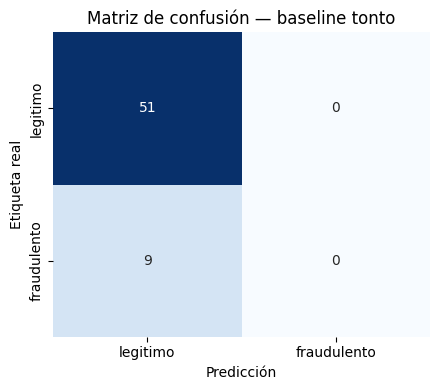

In [6]:
# Matriz de confusión: cuatro casillas. El falso negativo (fraude que se cuela) es el error caro.
import matplotlib.pyplot as plt
import seaborn as sns

clases = ['legitimo', 'fraudulento']
cm = confusion_matrix(y_val, pred, labels=clases)

fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases, yticklabels=clases, cbar=False, ax=ax)
ax.set_xlabel('Predicción'); ax.set_ylabel('Etiqueta real')
ax.set_title('Matriz de confusión — baseline tonto')
plt.tight_layout()
salida = RESULTADOS / '00_matriz_baseline_tonto.png'
plt.savefig(salida, dpi=120)
print('Figura guardada en:', salida)
plt.show()

## Qué aprendimos

1. **La exactitud engaña con clases desbalanceadas.** Un modelo que responde siempre "legítimo" logra exactitud alta y detecta **cero** fraudes.
2. **El F1 de la clase minoritaria (fraudulento) es lo que importa**, no la exactitud global.
3. **El falso negativo es el error caro**: un mensaje fraudulento que el modelo dejó pasar. Un falso positivo solo asusta de más.
4. Todas las métricas de la tesis salen de las cuatro casillas de la matriz de confusión.

**Entregable de la Semana 1:** este cuaderno corriendo de principio a fin. ✔️

**Siguiente:** Fase 2 — Motor de enlaces (`01_url.ipynb`), que no necesita el corpus y se puede empezar ya con datos públicos.